In [10]:
import pandas as pd
import numpy as np

In [3]:
url = "https://raw.githubusercontent.com/hankike/Premier_Prediction/refs/heads/main/data/cleaned_premier.csv"

df_premier = pd.read_csv(url)

In [11]:
df_premier['Date'] = pd.to_datetime(
    df_premier['Date'],
    dayfirst=True
)

df_premier = df_premier.sort_values('Date').reset_index(drop=True)

In [12]:
df_premier[['Date', 'HomeTeam', 'AwayTeam', 'FTR']].head()

,Date,HomeTeam,AwayTeam,FTR
0,2019-08-09,Liverpool,Norwich,H
1,2019-08-10,West Ham,Man City,A
2,2019-08-10,Bournemouth,Sheffield United,D
3,2019-08-10,Burnley,Southampton,H
4,2019-08-10,Crystal Palace,Everton,D


In [13]:
df_premier['FTR'].value_counts(normalize=True) * 100

FTR
H    43.421053
A    32.932331
D    23.646617
Name: proportion, dtype: float64

In [14]:
home = df_premier[[
    'Date', 'HomeTeam', 'FTR',
    'FTHG', 'FTAG', 'HS', 'HST', 'HC', 'HF'
]].copy()

home.columns = [
    'Date', 'Team', 'Result',
    'Goals_Scored', 'Goals_Conceded',
    'Shots', 'Shots_Target', 'Corners', 'Fouls'
]

home['Points'] = home['Result'].map({
    'H': 3,
    'D': 1,
    'A': 0
})

In [15]:
away = df_premier[[
    'Date', 'AwayTeam', 'FTR',
    'FTAG', 'FTHG', 'AS', 'AST', 'AC', 'AF'
]].copy()

away.columns = [
    'Date', 'Team', 'Result',
    'Goals_Scored', 'Goals_Conceded',
    'Shots', 'Shots_Target', 'Corners', 'Fouls'
]

away['Points'] = away['Result'].map({
    'A': 3,
    'D': 1,
    'H': 0
})

In [17]:
team_matches = pd.concat(
    [home, away],
    ignore_index=True
)

team_matches = team_matches.sort_values(
    ['Team', 'Date']
).reset_index(drop=True)

In [19]:
stats = [
    'Goals_Scored',
    'Goals_Conceded',
    'Shots',
    'Shots_Target',
    'Corners',
    'Fouls',
    'Points'
]

for stat in stats:
    team_matches[f'Avg_{stat}'] = (
        team_matches.groupby('Team')[stat]
        .transform(
            lambda x: x.shift(1).rolling(5, min_periods=1).mean()
        )
    )

In [21]:
df_premier['Season'] = (
    df_premier['Date'].dt.year.astype(str)
    + '-'
    + (df_premier['Date'].dt.year + 1).astype(str)
)

df_premier['Season'].value_counts().sort_index()

Season
2019-2020    199
2020-2021    336
2021-2022    408
2022-2023    361
2023-2024    412
2024-2025    372
2025-2026    378
2026-2027    194
Name: count, dtype: int64

In [22]:
feature_cols = [
    'Avg_Goals_Scored',
    'Avg_Goals_Conceded',
    'Avg_Shots',
    'Avg_Shots_Target',
    'Avg_Corners',
    'Avg_Fouls',
    'Avg_Points'
]

team_features = team_matches[
    ['Date', 'Team'] + feature_cols
].copy()

In [23]:
home_features = team_features.copy()

home_features = home_features.rename(
    columns={
        col: f'Home_{col}'
        for col in feature_cols
    }
)

home_features = home_features.rename(
    columns={'Team': 'HomeTeam'}
)

In [24]:
away_features = team_features.copy()

away_features = away_features.rename(
    columns={
        col: f'Away_{col}'
        for col in feature_cols
    }
)

away_features = away_features.rename(
    columns={'Team': 'AwayTeam'}
)

In [25]:
df_model = df_premier.merge(
    home_features,
    on=['Date', 'HomeTeam'],
    how='left'
)

df_model = df_model.merge(
    away_features,
    on=['Date', 'AwayTeam'],
    how='left'
)

In [26]:
df_model.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,Home_Avg_Corners,Home_Avg_Fouls,Home_Avg_Points,Away_Avg_Goals_Scored,Away_Avg_Goals_Conceded,Away_Avg_Shots,Away_Avg_Shots_Target,Away_Avg_Corners,Away_Avg_Fouls,Away_Avg_Points
0,E0,2019-08-09,20:00,Liverpool,Norwich,4,1,H,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,2019-08-10,12:30,West Ham,Man City,0,5,A,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,2019-08-10,15:00,Bournemouth,Sheffield United,1,1,D,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,2019-08-10,15:00,Burnley,Southampton,3,0,H,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,2019-08-10,15:00,Crystal Palace,Everton,0,0,D,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
for col in feature_cols:
    df_model[f'Diff_{col}'] = (
        df_model[f'Home_{col}']
        - df_model[f'Away_{col}']
    )

In [29]:
df_model[[
    'Date',
    'HomeTeam',
    'AwayTeam',
    'FTR',
    'Home_Avg_Points',
    'Away_Avg_Points'
]].head(15)

,Date,HomeTeam,AwayTeam,FTR,Home_Avg_Points,Away_Avg_Points
0,2019-08-09,Liverpool,Norwich,H,NaN,NaN
1,2019-08-10,West Ham,Man City,A,NaN,NaN
2,2019-08-10,Bournemouth,Sheffield United,D,NaN,NaN
3,2019-08-10,Burnley,Southampton,H,NaN,NaN
4,2019-08-10,Crystal Palace,Everton,D,NaN,NaN
5,2019-08-10,Watford,Brighton,A,NaN,NaN
6,2019-08-10,Tottenham,Aston Villa,H,NaN,NaN
7,2019-08-11,Newcastle,Arsenal,A,NaN,NaN
8,2019-08-11,Leicester,Wolves,D,NaN,NaN
9,2019-08-11,Man United,Chelsea,H,NaN,NaN


In [30]:
numeric_features = [
    'Home_Avg_Goals_Scored',
    'Home_Avg_Goals_Conceded',
    'Home_Avg_Shots',
    'Home_Avg_Shots_Target',
    'Home_Avg_Corners',
    'Home_Avg_Fouls',
    'Home_Avg_Points',

    'Away_Avg_Goals_Scored',
    'Away_Avg_Goals_Conceded',
    'Away_Avg_Shots',
    'Away_Avg_Shots_Target',
    'Away_Avg_Corners',
    'Away_Avg_Fouls',
    'Away_Avg_Points'
]

difference_features = [
    f'Diff_{col}' for col in feature_cols
]

categorical_features = [
    'HomeTeam',
    'AwayTeam'
]

features = (
    numeric_features
    + difference_features
    + categorical_features
)

X = df_model[features]
y = df_model['FTR']

In [31]:
print("First match:", df_model['Date'].min())
print("Last match:", df_model['Date'].max())

First match: 2019-08-09 00:00:00
Last match: 2026-05-24 00:00:00


In [32]:
season_start = (
    df_model['Date'].dt.year
    - (df_model['Date'].dt.month < 8).astype(int)
)

df_model['Season'] = (
    season_start.astype(str)
    + '-'
    + (season_start + 1).astype(str)
)

In [33]:
train_mask = df_model['Date'] < '2024-08-01'

val_mask = (
    (df_model['Date'] >= '2024-08-01') &
    (df_model['Date'] < '2025-08-01')
)

test_mask = df_model['Date'] >= '2025-08-01'

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

In [34]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 1900
Validation: 380
Testing: 380


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features + difference_features),
    ('cat', categorical_transformer, categorical_features)
])

In [38]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTraining results:")
print(y_train.value_counts())

print("\nTesting results:")
print(y_test.value_counts())

Training: 1900
Validation: 380
Testing: 380

Training results:
FTR
H    838
A    630
D    432
Name: count, dtype: int64

Testing results:
FTR
H    162
A    114
D    104
Name: count, dtype: int64


# Linear Regression Model

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [40]:
log_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [41]:
log_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['A','D','H']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Home_Avg_Goals_Scored','Home_Avg_Goals_Conceded','Home_Avg_Shots',..., 'Diff_Avg_Points','HomeTeam','AwayTeam']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'

In [42]:
log_predictions = log_model.predict(X_val)

In [43]:
print("Logistic Regression Accuracy:",
      accuracy_score(y_val, log_predictions))

Logistic Regression Accuracy: 0.4421052631578947


In [44]:
print(classification_report(
    y_val,
    log_predictions,
    labels=['H', 'D', 'A'],
    target_names=['Home Win', 'Draw', 'Away Win']
))

              precision    recall  f1-score   support

    Home Win       0.46      0.73      0.57       155
        Draw       0.14      0.03      0.05        93
    Away Win       0.45      0.39      0.42       132

    accuracy                           0.44       380
   macro avg       0.35      0.39      0.35       380
weighted avg       0.38      0.44      0.39       380



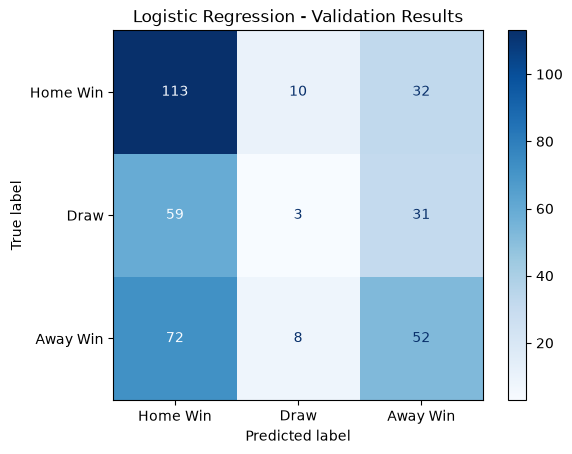

In [45]:
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_val,
    log_predictions,
    labels=['H', 'D', 'A']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Home Win', 'Draw', 'Away Win']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Validation Results')
plt.show()

# Random Forest

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [48]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['A','D','H']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Home_Avg_Goals_Scored','Home_Avg_Goals_Conceded','Home_Avg_Shots',..., 'Diff_Avg_Points','HomeTeam','AwayTeam']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'

In [49]:
rf_predictions = rf_model.predict(X_val)

In [51]:
print("Random Forest Accuracy:",
      accuracy_score(y_val, rf_predictions))

Random Forest Accuracy: 0.45263157894736844


In [50]:
print(classification_report(
    y_val,
    rf_predictions,
    labels=['H', 'D', 'A'],
    target_names=['Home Win', 'Draw', 'Away Win']
))

              precision    recall  f1-score   support

    Home Win       0.54      0.56      0.55       155
        Draw       0.22      0.16      0.19        93
    Away Win       0.46      0.53      0.49       132

    accuracy                           0.45       380
   macro avg       0.41      0.42      0.41       380
weighted avg       0.44      0.45      0.44       380



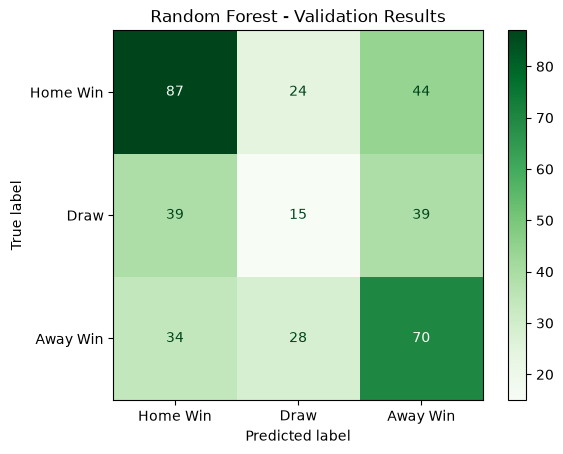

In [52]:
cm = confusion_matrix(
    y_val,
    rf_predictions,
    labels=['H', 'D', 'A']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Home Win', 'Draw', 'Away Win']
)

disp.plot(cmap='Greens')
plt.title('Random Forest - Validation Results')
plt.show()

In [53]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_val, log_predictions),
        accuracy_score(y_val, rf_predictions)
    ]
})

results.sort_values('Accuracy', ascending=False)

,Model,Accuracy
1,Random Forest,0.452632
0,Logistic Regression,0.442105


# Trying to make it better

In [54]:
from sklearn.metrics import balanced_accuracy_score, f1_score

print("Random Forest")
print("Accuracy:", accuracy_score(y_val, rf_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, rf_predictions))
print("Macro F1:", f1_score(y_val, rf_predictions, average='macro'))

print("\nLogistic Regression")
print("Accuracy:", accuracy_score(y_val, log_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, log_predictions))
print("Macro F1:", f1_score(y_val, log_predictions, average='macro'))

Random Forest
Accuracy: 0.45263157894736844
Balanced Accuracy: 0.4176278918214402
Macro F1: 0.41036967418546366

Logistic Regression
Accuracy: 0.4421052631578947
Balanced Accuracy: 0.3850765721733464
Macro F1: 0.3467000835421888


In [55]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_grid = {
    'classifier__n_estimators': [200, 300, 500, 700],
    'classifier__max_depth': [5, 8, 10, 15, 20, None],
    'classifier__min_samples_split': [5, 10, 15, 20],
    'classifier__min_samples_leaf': [2, 5, 10, 15],
    'classifier__max_features': ['sqrt', 'log2', None]
}

tscv = TimeSeriesSplit(n_splits=4)

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring='f1_macro',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

Fitting 4 folds for each of 20 candidates, totalling 80 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [5, 8, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': [2, 5, ...], 'classifier__min_samples_split': [5, 10, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than m

In [56]:
print(rf_search.best_params_)
print(rf_search.best_score_)

{'classifier__n_estimators': 200, 'classifier__min_samples_split': 15, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15}
0.44745058620709505


In [57]:
best_rf = rf_search.best_estimator_

tuned_predictions = best_rf.predict(X_val)

print(classification_report(
    y_val,
    tuned_predictions,
    labels=['H', 'D', 'A'],
    target_names=['Home Win', 'Draw', 'Away Win']
))

              precision    recall  f1-score   support

    Home Win       0.54      0.57      0.56       155
        Draw       0.18      0.11      0.13        93
    Away Win       0.46      0.55      0.50       132

    accuracy                           0.45       380
   macro avg       0.39      0.41      0.40       380
weighted avg       0.42      0.45      0.43       380



In [58]:
import pandas as pd

feature_importance = pd.Series(
    best_rf.named_steps['classifier'].feature_importances_,
    index=best_rf.named_steps['preprocessor'].get_feature_names_out()
).sort_values(ascending=False)

feature_importance.head(15)

num__Diff_Avg_Shots             0.061494
num__Diff_Avg_Shots_Target      0.053209
num__Diff_Avg_Corners           0.050934
num__Away_Avg_Shots             0.050529
num__Home_Avg_Shots             0.049768
num__Diff_Avg_Points            0.048694
num__Home_Avg_Shots_Target      0.041564
num__Diff_Avg_Fouls             0.040748
num__Away_Avg_Corners           0.040186
num__Away_Avg_Shots_Target      0.038885
num__Diff_Avg_Goals_Conceded    0.038548
num__Home_Avg_Corners           0.038341
num__Away_Avg_Fouls             0.036931
num__Home_Avg_Fouls             0.036160
num__Home_Avg_Points            0.034371
dtype: float64

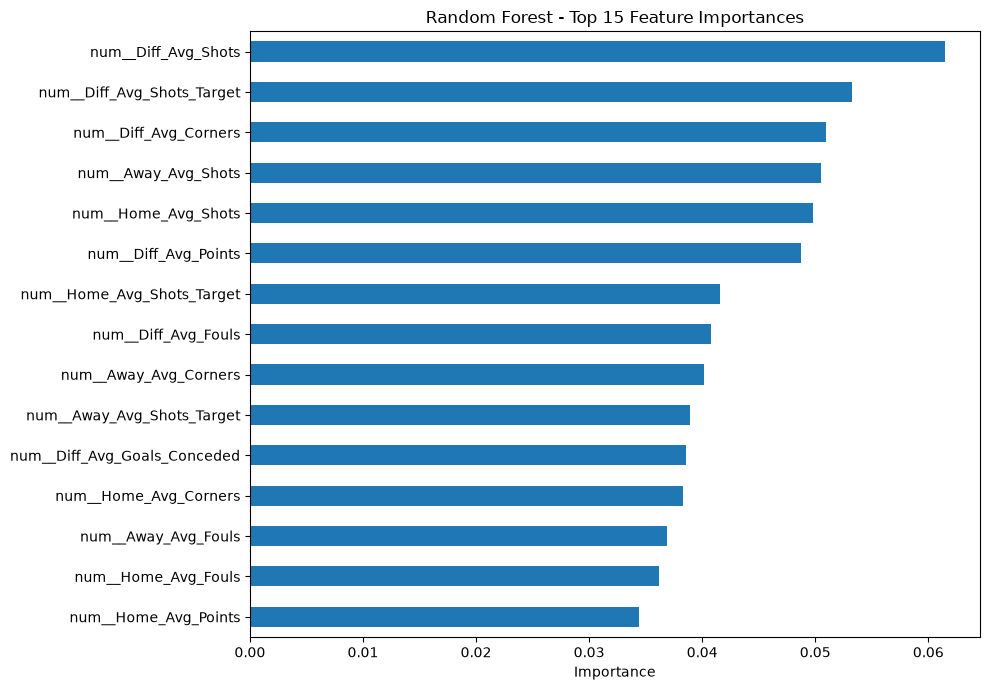

In [59]:
plt.figure(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind='barh'
)

plt.title('Random Forest - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()